# 03 — Laboratório Barnes–Hut

Este notebook usa exclusivamente o motor versionado `bh_engine_v1.py`. Ele foi
organizado para separar quatro atividades:

1. definir uma configuração;
2. executar ou carregar uma simulação;
3. analisar o arquivo `.npz` sem recalcular a dinâmica;
4. gerar figuras e GIFs independentemente.

O objetivo científico é verificar quando os braços e a barra são robustos e
quando dependem de parâmetros numéricos ou das condições iniciais.

## 1. Preparação do ambiente

Localmente, selecione a `.venv` do projeto como kernel. Quando aberto no
Google Colab, o notebook clona o repositório público para obter o mesmo motor.

Por padrão, resultados locais são gravados em `results/raw/`, que está fora do
Git. No Colab, ative `USE_GOOGLE_DRIVE` se quiser preservar os `.npz` após o
encerramento da sessão.

In [1]:
import json
import subprocess
import sys
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from matplotlib.animation import FuncAnimation, PillowWriter


REPOSITORY_URL = "https://github.com/Paulo-de-Souza/GalaxyDynamicsLab.git"
IN_COLAB = "google.colab" in sys.modules
USE_GOOGLE_DRIVE = False


def find_repository_root():
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "src" / "minigalaxy").exists():
            return candidate
    raise FileNotFoundError(
        "Não encontrei src/minigalaxy. Abra o notebook dentro do repositório."
    )


if IN_COLAB:
    REPOSITORY_ROOT = Path("/content/GalaxyDynamicsLab")
    if not REPOSITORY_ROOT.exists():
        subprocess.run(
            ["git", "clone", "--depth", "1", REPOSITORY_URL, str(REPOSITORY_ROOT)],
            check=True,
        )
    else:
        subprocess.run(
            ["git", "-C", str(REPOSITORY_ROOT), "pull", "--ff-only"],
            check=True,
        )
else:
    REPOSITORY_ROOT = find_repository_root()

sys.path.insert(0, str(REPOSITORY_ROOT / "src"))

from minigalaxy.bh_engine_v1 import (
    ENGINE_VERSION,
    KPC_MYR_TO_KM_S,
    NUMBA_AVAILABLE,
    SimulationConfig,
    load_result,
    result_filename,
    run_simulation,
    save_result,
)


if IN_COLAB and USE_GOOGLE_DRIVE:
    from google.colab import drive

    drive.mount("/content/drive")
    DATA_ROOT = Path("/content/drive/MyDrive/GalaxyDynamicsLab/results/raw")
else:
    DATA_ROOT = REPOSITORY_ROOT / "results" / "raw"

FIGURE_ROOT = REPOSITORY_ROOT / "figures" / "notebook03"
DATA_ROOT.mkdir(parents=True, exist_ok=True)
FIGURE_ROOT.mkdir(parents=True, exist_ok=True)

print("Raiz do projeto:", REPOSITORY_ROOT)
print("Resultados brutos:", DATA_ROOT)
print("Motor:", ENGINE_VERSION, "| Numba:", NUMBA_AVAILABLE)

Raiz do projeto: c:\Users\paulo\Documents\GalaxyDynamicsLab
Resultados brutos: c:\Users\paulo\Documents\GalaxyDynamicsLab\results\raw
Motor: 1.0.0 | Numba: True


## 2. Configurações experimentais

O caso `baseline` reproduz a configuração de alta resolução do Notebook 2:
$N=10000$, $\theta=0{,}5$, $\epsilon=0{,}20\,\mathrm{kpc}$ e dispersão inicial
$\sigma=0{,}025v_c$.

Os demais casos alteram um parâmetro por vez. Eles estão divididos
conceitualmente em:

- parâmetros numéricos: $\theta$, $\epsilon$ e $\Delta t$;
- robustez: semente aleatória;
- parâmetros dinâmicos: dispersão de velocidades.

Não execute todas as combinações automaticamente antes de inspecionar os casos
individuais.

In [2]:
BASELINE = SimulationConfig(
    n=10_000,
    m_halo=2.0e11,
    a_halo=6.0,
    m_disk=4.0e10,
    r_disk=3.0,
    r_min=0.35,
    r_max=15.0,
    velocity_dispersion_fraction=0.025,
    epsilon=0.20,
    dt=0.50,
    t_end=500.0,
    record_every=10,
    seed=20261027,
    theta=0.50,
    bucket_capacity=8,
    max_depth=48,
)

EXPERIMENTS = {
    # Referência
    "baseline": BASELINE,

    # Convergência e parâmetros numéricos
    "theta_030": replace(BASELINE, theta=0.30),
    "theta_070": replace(BASELINE, theta=0.70),
    "epsilon_015": replace(BASELINE, epsilon=0.15),
    "epsilon_030": replace(BASELINE, epsilon=0.30),
    "dt_025": replace(BASELINE, dt=0.25, record_every=20),
    "dt_100": replace(BASELINE, dt=1.00, record_every=5),

    # Robustez em relação ao ruído inicial
    "seed_20261028": replace(BASELINE, seed=20261028),
    "seed_20261029": replace(BASELINE, seed=20261029),

    # Temperatura dinâmica do disco
    "sigma_005": replace(BASELINE, velocity_dispersion_fraction=0.050),
    "sigma_010": replace(BASELINE, velocity_dispersion_fraction=0.100),
    "sigma_020": replace(BASELINE, velocity_dispersion_fraction=0.200),
}


def experiment_table(experiments):
    header = "| caso | N | theta | epsilon | dt | sigma/vc | seed |\n"
    separator = "|---|---:|---:|---:|---:|---:|---:|\n"
    rows = []
    for label, cfg in experiments.items():
        rows.append(
            f"| `{label}` | {cfg.n} | {cfg.theta:.2f} | {cfg.epsilon:.2f} | "
            f"{cfg.dt:.2f} | {cfg.velocity_dispersion_fraction:.3f} | {cfg.seed} |"
        )
    return header + separator + "\n".join(rows)


display(Markdown(experiment_table(EXPERIMENTS)))

| caso | N | theta | epsilon | dt | sigma/vc | seed |
|---|---:|---:|---:|---:|---:|---:|
| `baseline` | 10000 | 0.50 | 0.20 | 0.50 | 0.025 | 20261027 |
| `theta_030` | 10000 | 0.30 | 0.20 | 0.50 | 0.025 | 20261027 |
| `theta_070` | 10000 | 0.70 | 0.20 | 0.50 | 0.025 | 20261027 |
| `epsilon_015` | 10000 | 0.50 | 0.15 | 0.50 | 0.025 | 20261027 |
| `epsilon_030` | 10000 | 0.50 | 0.30 | 0.50 | 0.025 | 20261027 |
| `dt_025` | 10000 | 0.50 | 0.20 | 0.25 | 0.025 | 20261027 |
| `dt_100` | 10000 | 0.50 | 0.20 | 1.00 | 0.025 | 20261027 |
| `seed_20261028` | 10000 | 0.50 | 0.20 | 0.50 | 0.025 | 20261028 |
| `seed_20261029` | 10000 | 0.50 | 0.20 | 0.50 | 0.025 | 20261029 |
| `sigma_005` | 10000 | 0.50 | 0.20 | 0.50 | 0.050 | 20261027 |
| `sigma_010` | 10000 | 0.50 | 0.20 | 0.50 | 0.100 | 20261027 |
| `sigma_020` | 10000 | 0.50 | 0.20 | 0.50 | 0.200 | 20261027 |

## 3. Execução e cache

Cada configuração possui um nome e um hash. Se o `.npz` já existir, ele será
carregado em vez de recalculado, salvo quando `overwrite=True`.

O arquivo contém posições e velocidades de todos os snapshots, além de energia,
momento angular, quantis radiais, $A_1$, $A_2$ e metadados do ambiente.

In [3]:
RESULT_CACHE = {}


def experiment_path(label):
    if label not in EXPERIMENTS:
        raise KeyError(f"Experimento desconhecido: {label}")
    cfg = EXPERIMENTS[label]
    filename = f"{label}__{result_filename('tree', cfg)}"
    return DATA_ROOT / filename


def get_result(label, reload=False):
    if label in RESULT_CACHE and not reload:
        return RESULT_CACHE[label]

    path = experiment_path(label)
    if not path.exists():
        raise FileNotFoundError(
            f"Resultado não encontrado para '{label}'. Execute run_experiment('{label}')."
        )

    result = load_result(path)
    RESULT_CACHE[label] = result
    return result


def run_experiment(label, overwrite=False, progress_every=100):
    cfg = EXPERIMENTS[label]
    path = experiment_path(label)

    if path.exists() and not overwrite:
        print(f"Carregando resultado existente: {path.name}")
        return get_result(label, reload=True)

    print(f"Executando '{label}' com configuração {cfg.config_id}...")
    result = run_simulation(cfg, method="tree", progress_every=progress_every)
    save_result(result, path)
    RESULT_CACHE[label] = result
    print(f"Salvo em: {path}")
    print(f"Tempo da simulação: {float(result['runtime']):.2f} s")
    return result


def available_results():
    rows = []
    for label in EXPERIMENTS:
        path = experiment_path(label)
        if path.exists():
            rows.append((label, path.stat().st_size / 1024**2, path.name))

    if not rows:
        print("Nenhum resultado disponível. Escolha um caso na próxima célula.")
        return

    table = "| caso | tamanho [MiB] | arquivo |\n|---|---:|---|\n"
    table += "\n".join(
        f"| `{label}` | {size:.1f} | `{name}` |" for label, size, name in rows
    )
    display(Markdown(table))

In [16]:
# Coloque somente os casos que deseja executar agora.
# Exemplos: ["baseline"] ou ["theta_030", "sigma_010"]
RUN_LABELS = ["theta_030"]
OVERWRITE_RESULTS = False

for label in RUN_LABELS:
    run_experiment(label, overwrite=OVERWRITE_RESULTS)

available_results()

Executando 'theta_030' com configuração 9ac5be16f822...
tree: passo 100/1000
tree: passo 200/1000
tree: passo 300/1000
tree: passo 400/1000
tree: passo 500/1000
tree: passo 600/1000
tree: passo 700/1000
tree: passo 800/1000
tree: passo 900/1000
tree: passo 1000/1000
Salvo em: c:\Users\paulo\Documents\GalaxyDynamicsLab\results\raw\theta_030__resultado_tree_N10000_theta0.30_eps0.20_dt0.50_T500_sig0.025_seed20261027_9ac5be16f822.npz
Tempo da simulação: 168.04 s


| caso | tamanho [MiB] | arquivo |
|---|---:|---|
| `baseline` | 14.3 | `baseline__resultado_tree_N10000_theta0.50_eps0.20_dt0.50_T500_sig0.025_seed20261027_d621b85ab694.npz` |
| `theta_030` | 14.3 | `theta_030__resultado_tree_N10000_theta0.30_eps0.20_dt0.50_T500_sig0.025_seed20261027_9ac5be16f822.npz` |

## 4. Caso ativo e resumo

Escolha um resultado já calculado. As células de análise abaixo nunca chamam o
integrador; elas trabalham somente com o conteúdo do `.npz`.

In [17]:
ACTIVE_LABEL = "theta_030"

if experiment_path(ACTIVE_LABEL).exists():
    active_result = get_result(ACTIVE_LABEL)
    active_cfg = EXPERIMENTS[ACTIVE_LABEL]
    print(f"Caso ativo: {ACTIVE_LABEL} | snapshots: {len(active_result['time'])}")
else:
    active_result = None
    active_cfg = EXPERIMENTS[ACTIVE_LABEL]
    print(f"O caso '{ACTIVE_LABEL}' ainda não foi executado.")

Caso ativo: theta_030 | snapshots: 101



| métrica | valor |
|---|---:|
| tempo de execução | 168.04 s |
| $\Delta E/\lvert E_0\rvert$ | 3.795e-04 |
| $\Delta L_z/\lvert L_{z,0}\rvert$ | 4.620e-04 |
| $A_2$ máximo | 0.1547 |
| tempo do $A_2$ máximo | 490.0 Myr |
| $r_{10}$ final | 1.445 kpc |
| $r_{50}$ final | 4.921 kpc |
| $r_{90}$ final | 10.840 kpc |
| deriva máxima do centro de massa | 2.066e-01 kpc |


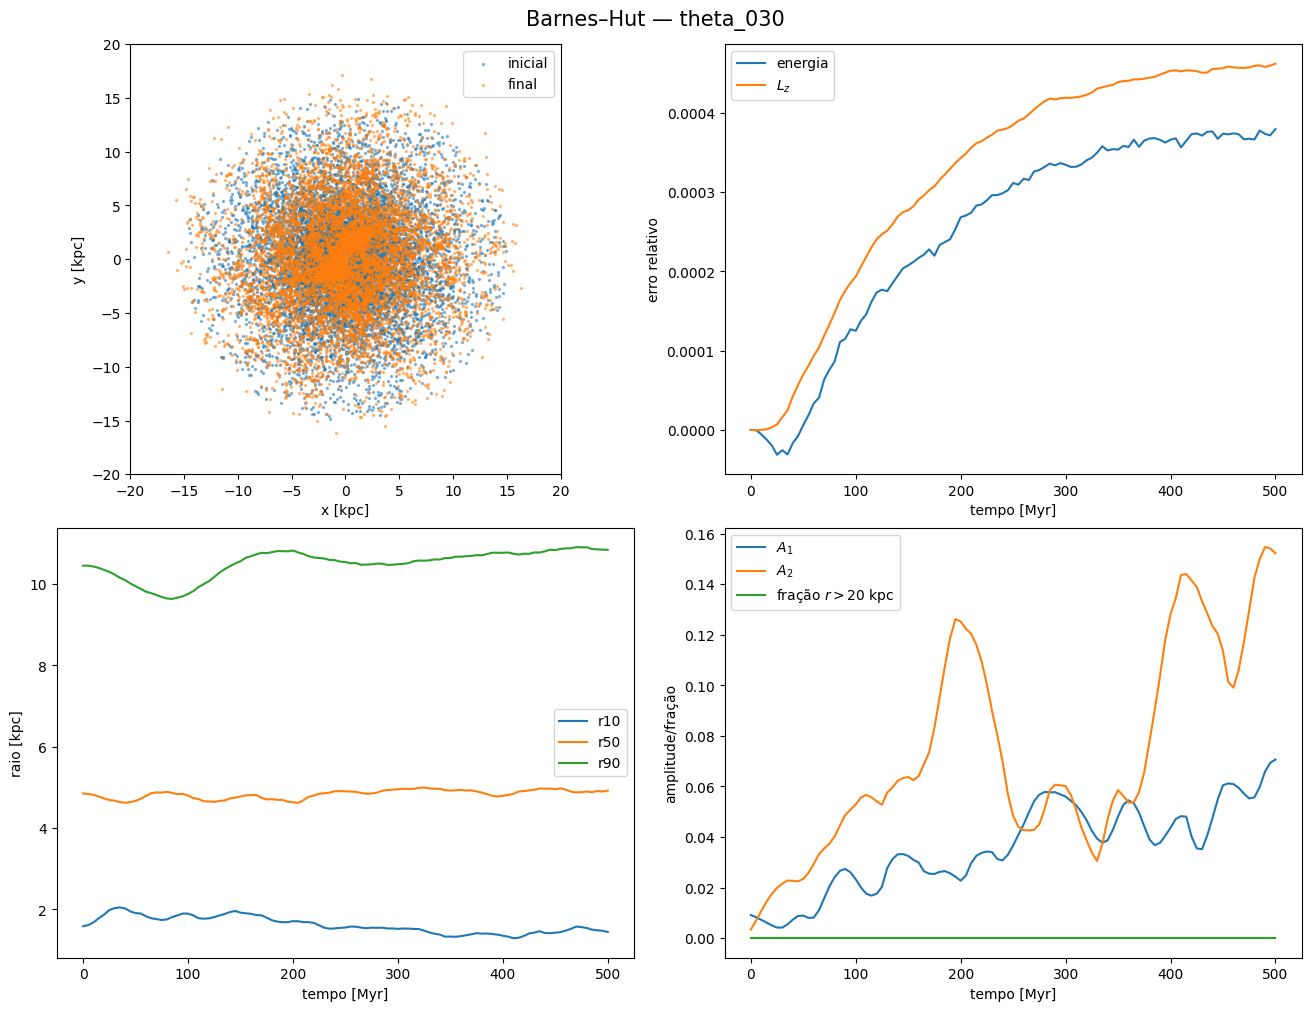

In [18]:
def summarize_result(label, result):
    energy = result["energy"]
    lz = result["lz"]
    positions = result["positions"]
    centers = np.mean(positions, axis=1)
    center_drift = np.linalg.norm(centers - centers[0], axis=1)
    peak_index = int(np.argmax(result["a2"]))

    return {
        "caso": label,
        "runtime_s": float(result["runtime"]),
        "dE": float((energy[-1] - energy[0]) / abs(energy[0])),
        "dLz": float((lz[-1] - lz[0]) / abs(lz[0])),
        "A2_max": float(result["a2"][peak_index]),
        "t_A2_max": float(result["time"][peak_index]),
        "r10_final": float(result["r_quantiles"][-1, 0]),
        "r50_final": float(result["r_quantiles"][-1, 1]),
        "r90_final": float(result["r_quantiles"][-1, 2]),
        "dr_com_max": float(np.max(center_drift)),
    }


def summary_markdown(summary):
    return fr'''
| métrica | valor |
|---|---:|
| tempo de execução | {summary['runtime_s']:.2f} s |
| $\Delta E/\lvert E_0\rvert$ | {summary['dE']:.3e} |
| $\Delta L_z/\lvert L_{{z,0}}\rvert$ | {summary['dLz']:.3e} |
| $A_2$ máximo | {summary['A2_max']:.4f} |
| tempo do $A_2$ máximo | {summary['t_A2_max']:.1f} Myr |
| $r_{{10}}$ final | {summary['r10_final']:.3f} kpc |
| $r_{{50}}$ final | {summary['r50_final']:.3f} kpc |
| $r_{{90}}$ final | {summary['r90_final']:.3f} kpc |
| deriva máxima do centro de massa | {summary['dr_com_max']:.3e} kpc |
'''


def plot_overview(label, result, limits=(-20, 20)):
    time_values = result["time"]
    energy = result["energy"]
    lz = result["lz"]
    pos_initial = result["positions"][0]
    pos_final = result["positions"][-1]

    fig, axes = plt.subplots(2, 2, figsize=(13, 10), constrained_layout=True)

    ax = axes[0, 0]
    ax.scatter(pos_initial[:, 0], pos_initial[:, 1], s=2, alpha=0.45, label="inicial")
    ax.scatter(pos_final[:, 0], pos_final[:, 1], s=2, alpha=0.45, label="final")
    ax.set(xlim=limits, ylim=limits, xlabel="x [kpc]", ylabel="y [kpc]")
    ax.set_aspect("equal")
    ax.legend()

    ax = axes[0, 1]
    ax.plot(time_values, (energy - energy[0]) / abs(energy[0]), label="energia")
    ax.plot(time_values, (lz - lz[0]) / abs(lz[0]), label=r"$L_z$")
    ax.set(xlabel="tempo [Myr]", ylabel="erro relativo")
    ax.legend()

    ax = axes[1, 0]
    for index, name in enumerate(("r10", "r50", "r90")):
        ax.plot(time_values, result["r_quantiles"][:, index], label=name)
    ax.set(xlabel="tempo [Myr]", ylabel="raio [kpc]")
    ax.legend()

    ax = axes[1, 1]
    ax.plot(time_values, result["a1"], label=r"$A_1$")
    ax.plot(time_values, result["a2"], label=r"$A_2$")
    ax.plot(time_values, result["frac_gt20"], label=r"fração $r>20$ kpc")
    ax.set(xlabel="tempo [Myr]", ylabel="amplitude/fração")
    ax.legend()

    fig.suptitle(f"Barnes–Hut — {label}", fontsize=15)
    return fig


if active_result is not None:
    display(Markdown(summary_markdown(summarize_result(ACTIVE_LABEL, active_result))))
    plot_overview(ACTIVE_LABEL, active_result)
    plt.show()

## 5. Modos azimutais

Para partículas de mesma massa, a amplitude global do modo $m$ é

$$
A_m(t)=\left|\frac{1}{N}\sum_{j=1}^{N}
\exp\left(im\varphi_j(t)\right)\right|.
$$

$m=1$ mede assimetria global; $m=2$ responde tanto a uma barra quanto a dois
braços. Os modos até $m=6$ ajudam a verificar se a morfologia é dominada por
uma única simetria ou por estrutura multiarmada.

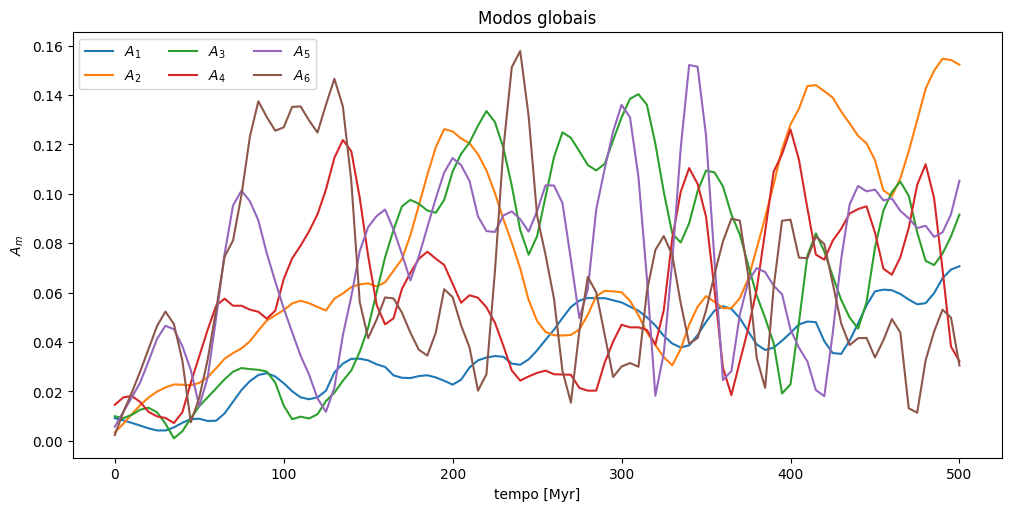

In [19]:
def global_fourier_modes(result, modes=range(1, 7), radial_range=None):
    positions = result["positions"].astype(np.float64)
    coefficients = {
        mode: np.full(len(positions), np.nan + 0j, dtype=np.complex128)
        for mode in modes
    }

    for time_index, pos in enumerate(positions):
        radius = np.linalg.norm(pos, axis=1)
        angle = np.arctan2(pos[:, 1], pos[:, 0])
        mask = np.ones(len(pos), dtype=bool)
        if radial_range is not None:
            r_min, r_max = radial_range
            mask = (radius >= r_min) & (radius < r_max)

        if np.count_nonzero(mask) == 0:
            continue
        for mode in modes:
            coefficients[mode][time_index] = np.mean(
                np.exp(1j * mode * angle[mask])
            )

    return coefficients


def plot_global_modes(result, modes=range(1, 7), radial_range=None):
    coefficients = global_fourier_modes(result, modes, radial_range)
    fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
    for mode in modes:
        ax.plot(result["time"], np.abs(coefficients[mode]), label=fr"$A_{mode}$")
    ax.set(xlabel="tempo [Myr]", ylabel=r"$A_m$")
    ax.legend(ncol=3)
    title = "Modos globais"
    if radial_range is not None:
        title += f" — {radial_range[0]:g} < r < {radial_range[1]:g} kpc"
    ax.set_title(title)
    return fig, coefficients


if active_result is not None:
    plot_global_modes(active_result)
    plt.show()

## 6. Estrutura radial de $A_2$

O valor global pode diminuir por cancelamento quando a fase do braço muda com
o raio. Por isso calculamos o coeficiente complexo em anéis:

$$
C_2(R,t)=\frac{1}{N_R}\sum_{j\in R}
\exp\left(2i\varphi_j(t)\right).
$$

A amplitude $\lvert C_2\rvert$ mede a força local do modo. Uma fase quase
constante em vários anéis internos é compatível com uma barra; uma fase que
varia sistematicamente com o raio é compatível com uma espiral.

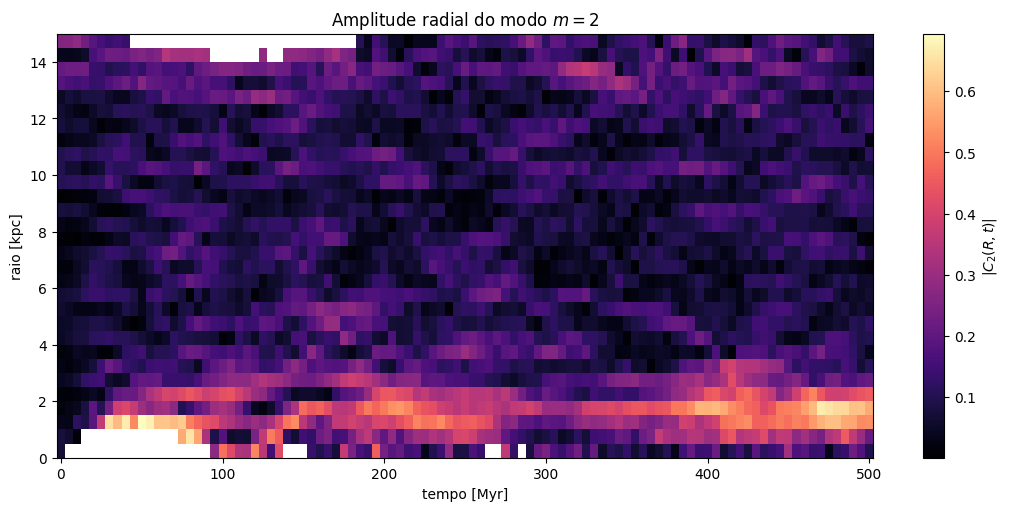

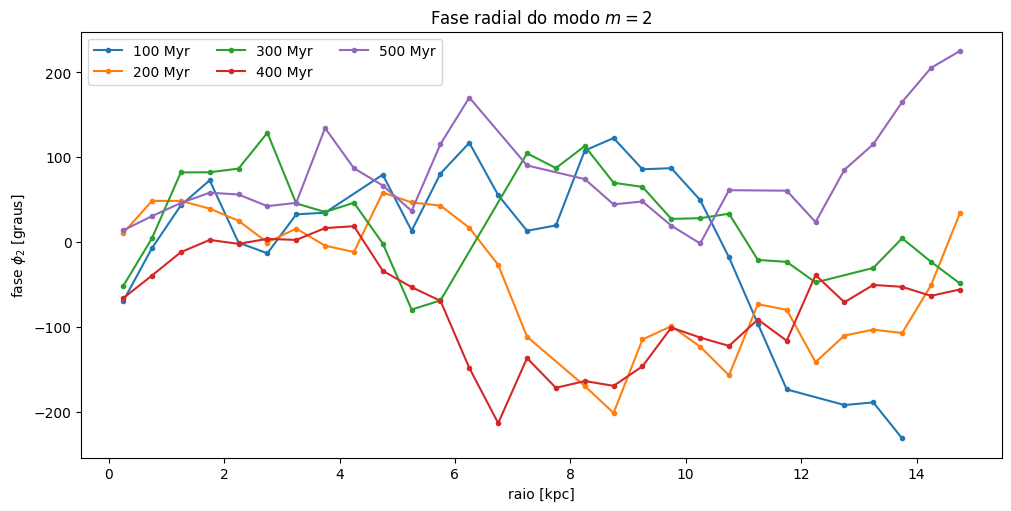

In [20]:
def radial_mode_map(result, mode=2, radial_edges=None, minimum_particles=30):
    if radial_edges is None:
        radial_edges = np.linspace(0.0, 15.0, 31)

    positions = result["positions"].astype(np.float64)
    n_times = len(positions)
    n_bins = len(radial_edges) - 1
    coefficients = np.full((n_times, n_bins), np.nan + 0j, dtype=np.complex128)
    counts = np.zeros((n_times, n_bins), dtype=int)

    for time_index, pos in enumerate(positions):
        radius = np.linalg.norm(pos, axis=1)
        angle = np.arctan2(pos[:, 1], pos[:, 0])
        bin_index = np.digitize(radius, radial_edges) - 1

        for radial_index in range(n_bins):
            mask = bin_index == radial_index
            count = np.count_nonzero(mask)
            counts[time_index, radial_index] = count
            if count >= minimum_particles:
                coefficients[time_index, radial_index] = np.mean(
                    np.exp(1j * mode * angle[mask])
                )

    radial_centers = 0.5 * (radial_edges[:-1] + radial_edges[1:])
    return radial_centers, coefficients, counts


def plot_radial_mode(result, mode=2, radial_edges=None):
    radius, coefficients, counts = radial_mode_map(
        result, mode=mode, radial_edges=radial_edges
    )
    amplitude = np.abs(coefficients)

    fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
    mesh = ax.pcolormesh(
        result["time"], radius, amplitude.T, shading="auto", cmap="magma"
    )
    fig.colorbar(mesh, ax=ax, label=fr"$|C_{mode}(R,t)|$")
    ax.set(xlabel="tempo [Myr]", ylabel="raio [kpc]")
    ax.set_title(fr"Amplitude radial do modo $m={mode}$")
    return fig, (radius, coefficients, counts)


def plot_radial_phase_profiles(result, radial_data, mode=2, times=(100, 200, 300, 400, 500), minimum_amplitude=0.03):
    radius, coefficients, _ = radial_data
    fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)

    for target_time in times:
        index = int(np.argmin(np.abs(result["time"] - target_time)))
        coefficient = coefficients[index]
        amplitude = np.abs(coefficient)
        phase = np.unwrap(np.angle(coefficient)) / mode
        mask = np.isfinite(phase) & (amplitude >= minimum_amplitude)
        ax.plot(radius[mask], np.degrees(phase[mask]), marker="o", ms=3, label=f"{result['time'][index]:g} Myr")

    ax.set(xlabel="raio [kpc]", ylabel=fr"fase $\phi_{mode}$ [graus]")
    ax.set_title(fr"Fase radial do modo $m={mode}$")
    ax.legend(ncol=3)
    return fig


if active_result is not None:
    _, radial_a2 = plot_radial_mode(active_result, mode=2)
    plt.show()
    plot_radial_phase_profiles(active_result, radial_a2, mode=2)
    plt.show()

## 7. Fase da barra e velocidade de padrão

Dentro de um raio escolhido, definimos

$$
\phi_2(t)=\frac{1}{2}\arg\left[
\sum_j \exp\left(2i\varphi_j(t)\right)
\right]
$$

e estimamos

$$
\Omega_p(t)=\frac{d\phi_2}{dt}.
$$

A fase só é confiável quando a amplitude interna de $m=2$ é suficientemente
grande. Pontos abaixo do limiar são omitidos do gráfico de $\Omega_p$.

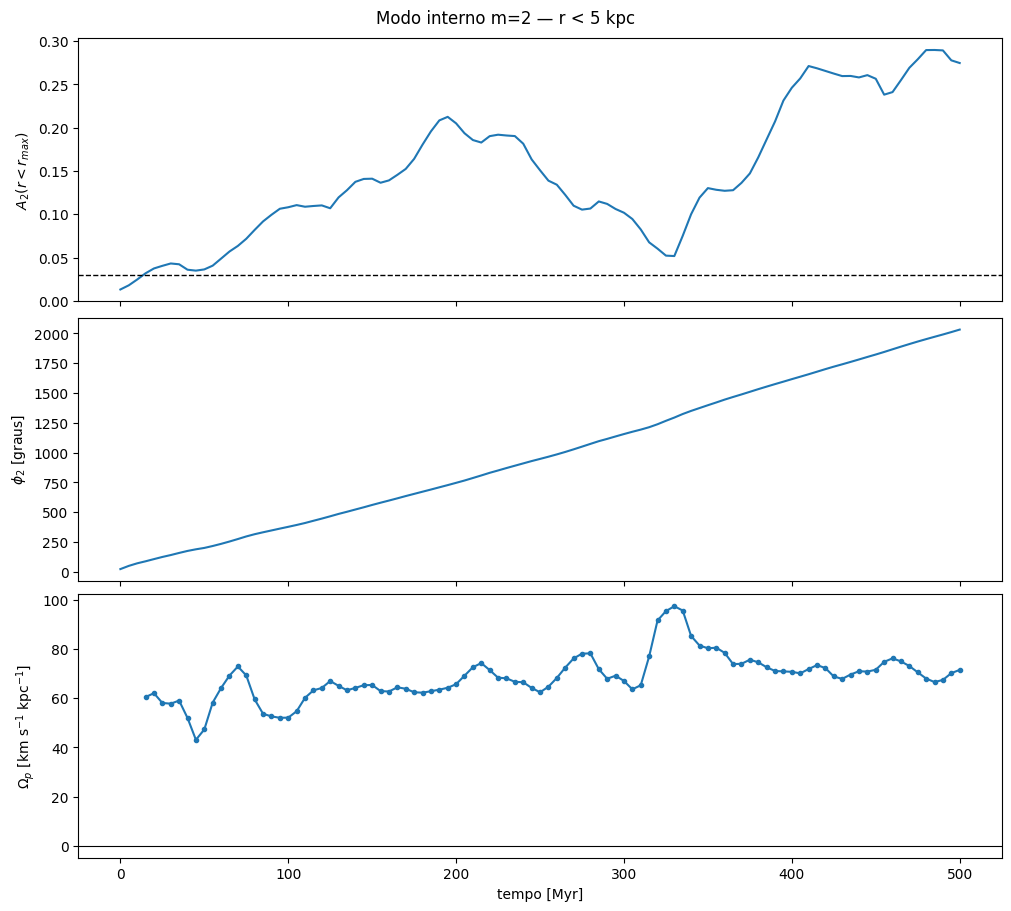

In [21]:
def inner_pattern_speed(result, r_max=5.0, minimum_amplitude=0.03):
    coefficient = global_fourier_modes(
        result, modes=(2,), radial_range=(0.0, r_max)
    )[2]
    amplitude = np.abs(coefficient)
    phase = np.unwrap(np.angle(coefficient)) / 2.0
    omega_myr = np.gradient(phase, result["time"])
    omega_kms_kpc = omega_myr * KPC_MYR_TO_KM_S
    reliable = amplitude >= minimum_amplitude
    return amplitude, phase, omega_kms_kpc, reliable


def plot_pattern_speed(result, r_max=5.0, minimum_amplitude=0.03):
    amplitude, phase, omega, reliable = inner_pattern_speed(
        result, r_max=r_max, minimum_amplitude=minimum_amplitude
    )

    fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=True, constrained_layout=True)
    axes[0].plot(result["time"], amplitude)
    axes[0].axhline(minimum_amplitude, color="black", ls="--", lw=1)
    axes[0].set_ylabel(r"$A_2(r<r_{max})$")

    axes[1].plot(result["time"], np.degrees(phase))
    axes[1].set_ylabel(r"$\phi_2$ [graus]")

    axes[2].plot(result["time"][reliable], omega[reliable], ".-")
    axes[2].set(xlabel="tempo [Myr]", ylabel=r"$\Omega_p$ [km s$^{-1}$ kpc$^{-1}$]")
    axes[2].axhline(0.0, color="black", lw=0.8)
    fig.suptitle(f"Modo interno m=2 — r < {r_max:g} kpc")
    return fig


if active_result is not None:
    plot_pattern_speed(active_result, r_max=5.0)
    plt.show()

## 8. Perfil inicial de Toomre

Como diagnóstico da temperatura dinâmica do disco estelar, usamos

$$
Q(R)=\frac{\sigma_R(R)\,\kappa(R)}{3{,}36\,G\,\Sigma(R)}.
$$

$\Sigma$ e $\sigma_R$ são estimados diretamente das partículas. A frequência
epicíclica $\kappa$ usa a mesma curva circular axisimétrica aproximada empregada
na construção das condições iniciais. O resultado é diagnóstico, não uma
descrição exata do disco depois que barra e braços tornam o sistema não
axisimétrico.

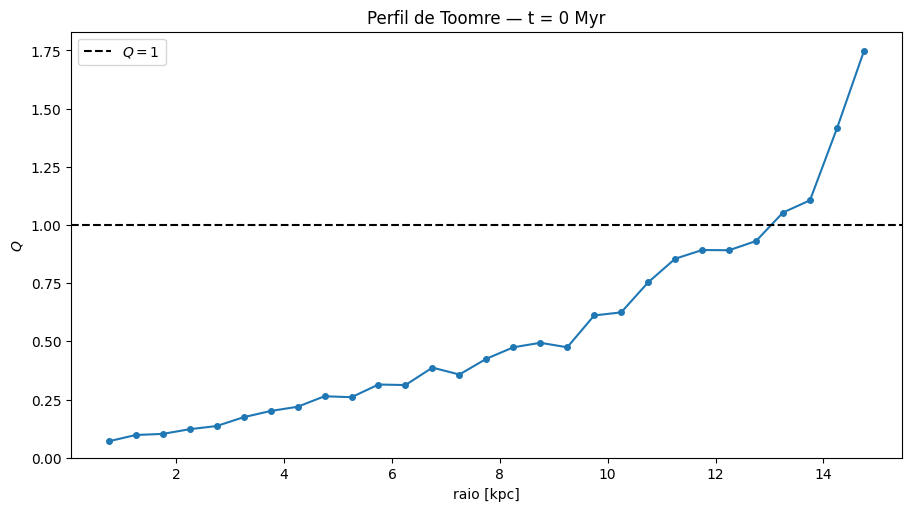

In [22]:
def reference_circular_speed(radius, cfg):
    vc2_halo = (
        4.498502151575286e-12
        * cfg.m_halo
        * radius**2
        / (radius**2 + cfg.a_halo**2) ** 1.5
    )
    scaled_radius = radius / cfg.r_disk
    enclosed_disk = cfg.m_disk * (
        1.0 - np.exp(-scaled_radius) * (1.0 + scaled_radius)
    )
    vc2_disk = 4.498502151575286e-12 * enclosed_disk / radius
    return np.sqrt(np.maximum(vc2_halo + vc2_disk, 0.0))


def toomre_profile(result, cfg, frame=0, radial_edges=None, minimum_particles=40):
    if radial_edges is None:
        radial_edges = np.linspace(0.5, 15.0, 30)

    pos = result["positions"][frame].astype(np.float64)
    vel = result["velocities"][frame].astype(np.float64)
    radius = np.linalg.norm(pos, axis=1)
    er = pos / radius[:, None]
    radial_velocity = np.sum(vel * er, axis=1)
    radial_centers = 0.5 * (radial_edges[:-1] + radial_edges[1:])
    particle_mass = cfg.m_disk / cfg.n

    surface_density = np.full(len(radial_centers), np.nan)
    sigma_r = np.full(len(radial_centers), np.nan)
    counts = np.zeros(len(radial_centers), dtype=int)

    for index in range(len(radial_centers)):
        mask = (radius >= radial_edges[index]) & (radius < radial_edges[index + 1])
        counts[index] = np.count_nonzero(mask)
        if counts[index] < minimum_particles:
            continue
        area = np.pi * (radial_edges[index + 1] ** 2 - radial_edges[index] ** 2)
        surface_density[index] = counts[index] * particle_mass / area
        sigma_r[index] = np.std(radial_velocity[mask], ddof=1)

    circular_speed = reference_circular_speed(radial_centers, cfg)
    omega2 = (circular_speed / radial_centers) ** 2
    kappa2 = radial_centers * np.gradient(omega2, radial_centers) + 4.0 * omega2
    kappa = np.sqrt(np.maximum(kappa2, 0.0))
    q_value = sigma_r * kappa / (
        3.36 * 4.498502151575286e-12 * surface_density
    )
    return radial_centers, q_value, sigma_r, surface_density, counts


def plot_toomre_profile(result, cfg, frame=0):
    radius, q_value, sigma_r, surface_density, counts = toomre_profile(
        result, cfg, frame=frame
    )
    fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
    ax.plot(radius, q_value, marker="o", ms=4)
    ax.axhline(1.0, color="black", ls="--", label=r"$Q=1$")
    ax.set(xlabel="raio [kpc]", ylabel=r"$Q$")
    ax.set_ylim(bottom=0.0)
    ax.set_title(f"Perfil de Toomre — t = {result['time'][frame]:g} Myr")
    ax.legend()
    return fig


if active_result is not None:
    plot_toomre_profile(active_result, active_cfg, frame=0)
    plt.show()

## 9. Comparação entre experimentos

Esta seção compara arquivos já existentes. Ela não executa automaticamente os
casos ausentes.

| caso | runtime [s] | dE | dLz | A2 máximo | t(A2 máximo) [Myr] | r50 final [kpc] |
|---|---:|---:|---:|---:|---:|---:|
| `baseline` | 66.8 | 9.16e-04 | 9.46e-04 | 0.148 | 445.0 | 4.864 |
| `theta_030` | 168.0 | 3.80e-04 | 4.62e-04 | 0.155 | 490.0 | 4.921 |

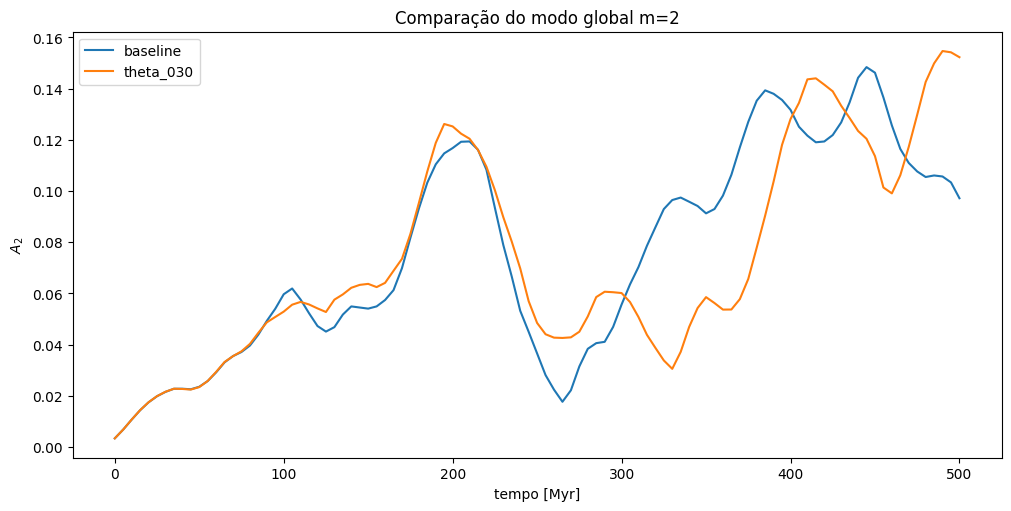

In [23]:
def comparison_markdown(labels):
    header = (
        "| caso | runtime [s] | dE | dLz | A2 máximo | t(A2 máximo) [Myr] | r50 final [kpc] |\n"
    )
    separator = "|---|---:|---:|---:|---:|---:|---:|\n"
    rows = []
    for label in labels:
        summary = summarize_result(label, get_result(label))
        rows.append(
            f"| `{label}` | {summary['runtime_s']:.1f} | {summary['dE']:.2e} | "
            f"{summary['dLz']:.2e} | {summary['A2_max']:.3f} | "
            f"{summary['t_A2_max']:.1f} | {summary['r50_final']:.3f} |"
        )
    return header + separator + "\n".join(rows)


def plot_a2_comparison(labels):
    fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
    for label in labels:
        result = get_result(label)
        ax.plot(result["time"], result["a2"], label=label)
    ax.set(xlabel="tempo [Myr]", ylabel=r"$A_2$")
    ax.legend()
    ax.set_title("Comparação do modo global m=2")
    return fig


COMPARE_LABELS = ["baseline", "theta_030"]
available_to_compare = all(experiment_path(label).exists() for label in COMPARE_LABELS)

if available_to_compare:
    display(Markdown(comparison_markdown(COMPARE_LABELS)))
    plot_a2_comparison(COMPARE_LABELS)
    plt.show()
else:
    print("Comparação aguardando:", [
        label for label in COMPARE_LABELS if not experiment_path(label).exists()
    ])

## 10. GIFs independentes

As funções abaixo recebem resultados já calculados. Títulos, limites, tamanho
dos pontos, quantidade de frames e taxa de quadros podem ser alterados sem
executar novamente a simulação.

In [24]:
def selected_frame_indices(n_snapshots, frame_stride=1, max_frames=None):
    indices = np.arange(0, n_snapshots, frame_stride, dtype=int)
    if indices[-1] != n_snapshots - 1:
        indices = np.append(indices, n_snapshots - 1)
    if max_frames is not None and len(indices) > max_frames:
        indices = np.unique(
            np.linspace(0, n_snapshots - 1, max_frames).round().astype(int)
        )
    return indices


from IPython.display import Image, display


def _point_size(n):
    """Ajusta automaticamente o tamanho dos pontos conforme N."""
    return float(np.clip(8000.0 / n, 0.45, 6.0))


def make_single_gif(
    result,
    output_path,
    title=None,
    lim=20.0,
    color="#fbbf24",
    max_frames=101,
    fps=20,
    dpi=100,
):
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)

    positions = result["positions"]
    times = result["time"]
    n_particles = positions.shape[1]

    frame_ids = np.linspace(
        0,
        len(times) - 1,
        min(max_frames, len(times)),
        dtype=int,
    )

    if title is None:
        cfg = json.loads(result["config_json"].item())
        title = (
            f"Barnes–Hut — N={cfg['n']}, "
            f"θ={cfg['theta']:.2f}, "
            f"ε={cfg['epsilon']:.2f} kpc"
        )

    fig, ax = plt.subplots(
        figsize=(6.2, 6.2),
        constrained_layout=True,
    )

    ax.set(
        xlim=(-lim, lim),
        ylim=(-lim, lim),
        xlabel="x [kpc]",
        ylabel="y [kpc]",
    )
    ax.set_aspect("equal")
    ax.set_title(title)

    # Fundo escuro usado nos GIFs do Notebook 2.
    ax.set_facecolor("#050814")

    scatter = ax.scatter(
        [],
        [],
        s=_point_size(n_particles),
        c=color,
        alpha=0.80,
        edgecolors="none",
    )

    clock = ax.text(
        0.03,
        0.96,
        "",
        transform=ax.transAxes,
        color="white",
        fontsize=11,
        va="top",
    )

    def update(frame_index):
        snapshot = frame_ids[frame_index]

        scatter.set_offsets(positions[snapshot])
        clock.set_text(f"t = {times[snapshot]:.0f} Myr")

        return scatter, clock

    animation = FuncAnimation(
        fig,
        update,
        frames=len(frame_ids),
        interval=1000 / fps,
        blit=True,
        repeat=True,
    )

    animation.save(
        output_path,
        writer=PillowWriter(fps=fps),
        dpi=dpi,
    )

    plt.close(fig)

    print(f"GIF salvo em: {output_path}")
    return output_path


def make_comparison_gif(
    left_result,
    right_result,
    output_path,
    titles=("caso A", "caso B"),
    limits=(-20, 20),
    point_size=1.5,
    colors=("#5DADE2", "#F5B041"),
    max_frames=101,
    fps=20,
    dpi=100,
):
    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    final_time = min(left_result["time"][-1], right_result["time"][-1])
    common_times = np.linspace(0.0, final_time, max_frames)
    left_indices = [int(np.argmin(abs(left_result["time"] - t))) for t in common_times]
    right_indices = [int(np.argmin(abs(right_result["time"] - t))) for t in common_times]

    fig, axes = plt.subplots(1, 2, figsize=(12, 6), constrained_layout=True)
    scatters = []
    time_texts = []
    for ax, title, color in zip(axes, titles, colors):
        scatters.append(
            ax.scatter([], [], s=point_size, c=color, alpha=0.85, linewidths=0)
        )
        time_texts.append(ax.text(0.03, 0.96, "", transform=ax.transAxes, va="top"))
        ax.set(xlim=limits, ylim=limits, xlabel="x [kpc]", ylabel="y [kpc]")
        ax.set_aspect("equal")
        ax.set_title(title)

    def update(frame_number):
        left_index = left_indices[frame_number]
        right_index = right_indices[frame_number]
        scatters[0].set_offsets(left_result["positions"][left_index])
        scatters[1].set_offsets(right_result["positions"][right_index])
        time_texts[0].set_text(f"t = {left_result['time'][left_index]:.0f} Myr")
        time_texts[1].set_text(f"t = {right_result['time'][right_index]:.0f} Myr")
        return (*scatters, *time_texts)

    animation = FuncAnimation(
        fig, update, frames=len(common_times), interval=1000 / fps, blit=True
    )
    animation.save(output_path, writer=PillowWriter(fps=fps), dpi=dpi)
    plt.close(fig)
    print("GIF comparativo salvo em:", output_path)
    return output_path

In [25]:
# Estas chaves permanecem desligadas por padrão.
GENERATE_SINGLE_GIF = True
SINGLE_GIF_LABEL = "theta_030"

GENERATE_COMPARISON_GIF = False
COMPARISON_GIF_LABELS = ("baseline", "theta_030")

if GENERATE_SINGLE_GIF:
    result_for_gif = get_result(SINGLE_GIF_LABEL)

    gif_path = make_single_gif(
        result=result_for_gif,
        output_path=DATA_ROOT / "gifs" / f"{SINGLE_GIF_LABEL}.gif",
        title="Minigaláxia autogravitante — Barnes–Hut",
        lim=20.0,
        color="#fbbf24",
        max_frames=101,
        fps=20,
        dpi=100,
    )

if GENERATE_COMPARISON_GIF:
    left_label, right_label = COMPARISON_GIF_LABELS
    make_comparison_gif(
        get_result(left_label),
        get_result(right_label),
        DATA_ROOT / "gifs" / f"{left_label}_vs_{right_label}.gif",
        titles=(left_label, right_label),
        limits=(-20, 20),
        point_size=1.5,
        max_frames=101,
    )

GIF salvo em: c:\Users\paulo\Documents\GalaxyDynamicsLab\results\raw\gifs\theta_030.gif


## 11. Protocolo recomendado

Uma sequência econômica para testar a robustez da galáxia barrada é:

1. executar `baseline` e confirmar o resultado conhecido;
2. executar `theta_030` com a mesma semente;
3. comparar $A_2(t)$, energia, $L_z$ e o mapa $A_2(R,t)$;
4. repetir com `seed_20261028` e `seed_20261029`;
5. estudar `sigma_005`, `sigma_010` e `sigma_020`;
6. usar `dt_025` apenas nos casos que exigirem confirmação temporal;
7. gerar GIFs somente para resultados selecionados.

Se a orientação e o instante exato dos braços mudarem com a semente, mas o
crescimento de $A_2$ permanecer, a instabilidade é robusta. Se o modo diminuir
com o aumento da dispersão e do perfil $Q$, teremos uma explicação física para
o aparecimento da barra, e não somente uma animação visualmente semelhante a
uma galáxia.